<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from pathlib import Path
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 8: Speech and Audio Data**

**Authors:** *Hemanthi Paidi, Lino Kaiser, Sebastian Droz*

### Instructor review (2026-10-08)

This notebook (Group 8 – Speech and Audio Data) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- STFT: discrete formula, meaning of `n_fft` / `hop_length` / window, resolution Δf = sr/n_fft and Δt = hop/sr, time–frequency trade-off, magnitude vs. power vs. dB (+ runnable example with a short vs. long window on the librosa speech clip)
- MFCC: formulas for the Mel scale, filterbank energies, log, DCT-II and coefficient truncation; brief remark on deltas; per-coefficient standardization (CMVN)
- Graceful handling of a missing `music/` folder; majority-class baseline, naive vs. grouped (artist/work) cross-validation and interpretation of the result for the genre classifier

**Corrected**
- Genre classifier: 2 050 STFT features for 14 recordings with a single 50 % split (7 test files) replaced by 26 MFCC summary features (mean + std of 13 MFCCs) and leave-one-group-out CV (artist/work as group, since 7 classical files are movements of one work), compared with a majority baseline
- Music cell overwrote the speech variables `y`, `sr` (and reused `y` for labels) – renamed
- References to the removed recognizer/microphone sources ([10]–[12]) fixed

**Revised for clarity**
- Introduction, librosa, STFT and MFCC overview texts: references to the live microphone/recognizer demo replaced by the example clip
- MFCC step-by-step cells now use librosa's standard pipeline on `librosa.ex('libri1')` instead of PocketSphinx-specific settings (pre-emphasis, int16 scaling, custom filter weights, liftering)
- 'What does the example show?', Takeaways and References

**Removed (beyond course scope)**
- Microphone recording (`sounddevice`) and speech recognition with PocketSphinx (`Decoder`, `process_cep`, model-specific settings) incl. the `%pip install` cell

The two music cells were executed on the 14 local recordings (`music/classic`, `music/rock`, not part of the repository).


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/08_Speech_and_Audio_Data.png" width="1200"/>

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *reference to the removed speech-recognizer demo replaced*

## Introduction

**What is it about?**
Audio recordings contain thousands of samples per second. Audio feature extraction turns these samples into representations that are easier for machine learning models to use. The Short-Time Fourier Transform (STFT) shows how frequency content changes over time. Mel Frequency Cepstral Coefficients (MFCCs) summarize the broad spectral shape of short audio frames. We use `librosa` to explore these representations.

**Where is it used?**
Typical applications include speech recognition, speaker identification, keyword spotting, music analysis, environmental sound classification, and monitoring machines through their sounds.

**Why does it matter for machine learning?**
Useful features make sound patterns easier to compare and learn. In this notebook, we follow a speech clip from its waveform via the STFT to MFCC features, and then use MFCC summary features in a small music-genre classifier.

## (i) Audio feature extraction using `librosa`



<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *live-demo reference replaced*

### Introduction to `librosa`

`librosa` is a Python library for **audio and music signal processing**. It can load recordings, visualize waveforms, analyze frequency content, and extract features for machine learning.

A waveform is a sequence of amplitude values sampled over time. Our workflow converts this signal into increasingly compact representations:

**Audio -> waveform -> frequency spectrum -> log-Mel bands -> MFCC features**

The main steps are:

1. **Load audio:** `librosa.load()` returns the samples and their sampling rate.
2. **Inspect the waveform:** Plot the amplitude over time.
3. **Analyze frequencies:** `librosa.stft()` analyzes short, overlapping frames. A spectrogram visualizes the strength of frequencies over time.
4. **Group frequencies:** Mel bands combine nearby frequencies using a scale inspired by human hearing. Logarithmic compression balances their range.
5. **Extract features:** `librosa.feature.mfcc()` transforms the log-Mel representation into coefficients describing its broad spectral shape.

First, load a supplied speech clip and plot its waveform. Sections (ii) and (iii) apply the remaining steps to the **same clip**.

In [2]:
# [REVISED] install line commented out (no reinstall on every run)
# %pip install "librosa==0.11.0"   # uncomment only if librosa is not installed

In [3]:
import librosa
import librosa.display

# Load an example speech recording provided by librosa
y, sr = librosa.load(librosa.ex("libri1"), sr=None)

print(f"Sampling rate: {sr} Hz")
print(f"Number of samples: {len(y)}")
print(f"Duration: {len(y) / sr:.2f} seconds")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sampling rate: 22050 Hz
Number of samples: 327222
Duration: 14.84 seconds


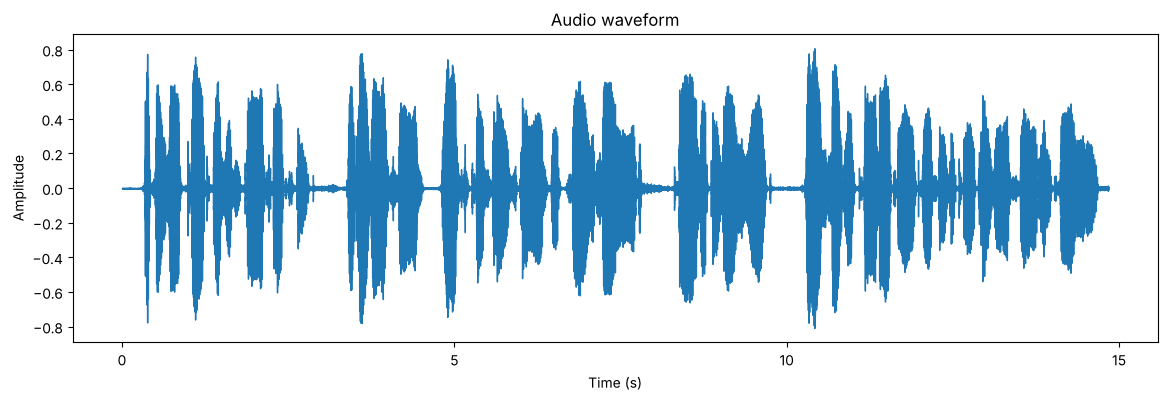

In [4]:
# Plot the waveform

plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    y,
    sr=sr
)

plt.title("Audio waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *live-demo reference replaced*

## (ii) Short-Time Fourier Transform (STFT)

The STFT measures the frequencies present in short, overlapping windows of audio. A **spectrogram** shows how their strengths change over time: time is on the horizontal axis, frequency on the vertical axis, and color indicates strength.

This frequency representation is the starting point for the MFCC pipeline below. We compute it for the speech clip and, as a second example, for two music recordings. [2]

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### STFT: definition and parameters

The signal $x[n]$ is cut into frames of length $N$ = `n_fft`, shifted by $H$ = `hop_length`
samples; each frame is multiplied by a window $w[n]$ (librosa default: Hann) and Fourier-transformed:

$$
X[m,k] \;=\; \sum_{n=0}^{N-1} x[n + mH]\; w[n]\; e^{-j 2\pi k n / N},
\qquad k = 0,\dots,\tfrac{N}{2},\quad m = \text{frame index}.
$$

`librosa.stft` returns the complex matrix $X$ with shape `(1 + n_fft//2, n_frames)`
(with `center=True` frames are centred, i.e. $n_\text{frames} = 1 + \lfloor \text{len}(x)/H \rfloor$).

| Quantity | Formula | Example: `sr` = 22 050 Hz, `n_fft` = 512, `hop` = 256 |
|---|---|---|
| frequency-bin spacing | $\Delta f = \text{sr}/N$ | 43 Hz |
| window (frame) length | $T_w = N/\text{sr}$ | 23 ms |
| time step between frames | $\Delta t = H/\text{sr}$ | 11.6 ms |

- **Time–frequency trade-off:** a long window gives fine frequency resolution but smears fast
  changes in time; a short window localises events in time but blurs frequencies
  ($\Delta t \cdot \Delta f$ cannot be made arbitrarily small). Speech: 20–30 ms windows,
  ≈ 10 ms hop; music/harmonics: longer windows (librosa default `n_fft=2048` ≈ 93 ms at 22 kHz).
  The ability to *separate* two tones is set by the window length (`win_length`); zero-padding
  (`n_fft > win_length`) only interpolates the spectrum.
- **Window:** tapering the frame edges reduces spectral leakage; the hop is usually $N/4$–$N/2$
  (overlapping frames).
- **Magnitude vs. power vs. dB:** features drop the phase and use the magnitude $|X|$ or the
  power $|X|^2$. In dB, $20\log_{10}(|X|/\text{ref}) = 10\log_{10}(|X|^2/\text{ref}^2)$:
  use `amplitude_to_db` for $|X|$ and `power_to_db` for $|X|^2$ — mixing them doubles/halves
  the dB values. `ref=np.max` puts the loudest bin at 0 dB.

STFT shape: (257, 1279)  (frequency bins x frames), dtype complex64
Δf = sr/n_fft = 43.1 Hz,  window = 23.2 ms,  Δt = hop/sr = 11.6 ms


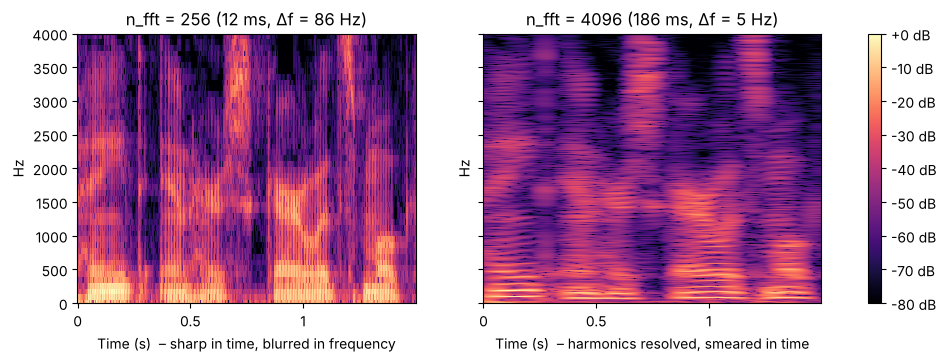

In [5]:
# [ADDED]
N_FFT, HOP = 512, 256                       # 23 ms window, 11.6 ms hop at sr = 22 050 Hz
X = librosa.stft(y, n_fft=N_FFT, hop_length=HOP, window="hann")   # complex, (1 + N_FFT//2, frames)
power = np.abs(X) ** 2                      # power spectrogram |X|^2
print(f"STFT shape: {X.shape}  (frequency bins x frames), dtype {X.dtype}")
print(f"Δf = sr/n_fft = {sr / N_FFT:.1f} Hz,  window = {1000 * N_FFT / sr:.1f} ms,  "
      f"Δt = hop/sr = {1000 * HOP / sr:.1f} ms")

# Time-frequency trade-off on a 1.5 s excerpt: short vs. long window (same hop)
seg = y[int(1.0 * sr):int(2.5 * sr)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, n_fft in zip(axes, [256, 4096]):
    S_db = librosa.power_to_db(np.abs(librosa.stft(seg, n_fft=n_fft, hop_length=64)) ** 2, ref=np.max)
    img = librosa.display.specshow(S_db, sr=sr, hop_length=64, x_axis="time", y_axis="hz",
                                   cmap="magma", ax=ax)
    ax.set(title=f"n_fft = {n_fft} ({1000 * n_fft / sr:.0f} ms, Δf = {sr / n_fft:.0f} Hz)", ylim=(0, 4000))
fig.colorbar(img, ax=axes, format="%+2.0f dB")
axes[0].set_xlabel("Time (s)  – sharp in time, blurred in frequency")
axes[1].set_xlabel("Time (s)  – harmonics resolved, smeared in time")
plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Second example – music spectrograms (local files).** The next cell shows the STFT of one
classical and one rock recording from the local folders `music/classic` and `music/rock`
(not part of this repository; the cell prints a message and skips if they are missing).
Note the sharp horizontal harmonic lines of the classical piece versus the broadband,
percussive vertical structures in the rock piece.

classic: 9 files
rock: 5 files


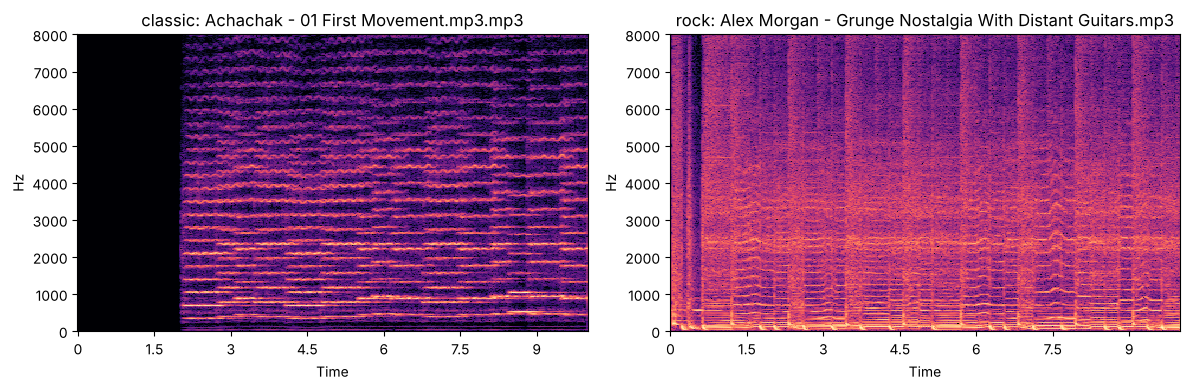

In [ ]:
# [CORRECTED] missing folders now fail gracefully; music clips use their own variable names
# (the original cell overwrote the speech signal `y`, `sr` and reused `y` for the labels).
# Your folders:
# music/classic/
# music/rock/
from pathlib import Path
DATA_DIR = Path("music")
GENRES = ["classic", "rock"]
AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".ogg", ".m4a"}
SAMPLE_RATE = 22050
CLIP_SECONDS = 10

# Find audio files
files = {
    genre: sorted(
        p for p in (DATA_DIR / genre).rglob("*")
        if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS
    )
    for genre in GENRES
}

for genre, paths in files.items():
    print(f"{genre}: {len(paths)} files")

if any(len(paths) == 0 for paths in files.values()):
    print(f"No audio files found in {DATA_DIR.resolve()}/<genre>/ – the music examples are skipped. "
          "Put a few audio files into music/classic and music/rock to run them.")
    files = None
else:
    # Display an STFT spectrogram for one example from each genre
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, genre in zip(axes, GENRES):
        y_clip, sr_clip = librosa.load(files[genre][0], sr=SAMPLE_RATE, mono=True, duration=CLIP_SECONDS)
        D = librosa.stft(y_clip, n_fft=2048, hop_length=512)
        D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
        librosa.display.specshow(
            D_db, sr=sr_clip, hop_length=512, x_axis="time", y_axis="hz",
            cmap="magma", ax=ax
        )
        ax.set_title(f"{genre}: {files[genre][0].name}")
        ax.set_ylim(0, 8000)
    plt.tight_layout()
    plt.show()

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *demo reference replaced*

## (iii) Mel Frequency Cepstral Coefficients (MFCC)

### What are MFCCs, and what is their goal?

**MFCCs describe the broad frequency pattern of each short audio frame using a small set of numbers.** A machine learning model can use their sequence to distinguish words, speakers, or other sounds.

Imagine saying **"ah"** and **"ee"** at the same pitch. Your tongue and mouth change shape, which changes which frequencies become strong. MFCCs help describe these differences. [1, 6]

The name describes the representation:

| Term | Meaning |
|---|---|
| **Mel frequency** | A frequency scale inspired by how people perceive pitch differences. |
| **Cepstral** | A representation obtained by transforming a logarithmic spectrum. |
| **Coefficients** | The numbers returned by that transform. |

The goal is a **compact description of sound** that a model can learn from. Extracting these features and learning from them (e.g. recognizing words or genres) are separate steps.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *power spectrum named explicitly; demo reference replaced*

### The full pipeline at a glance

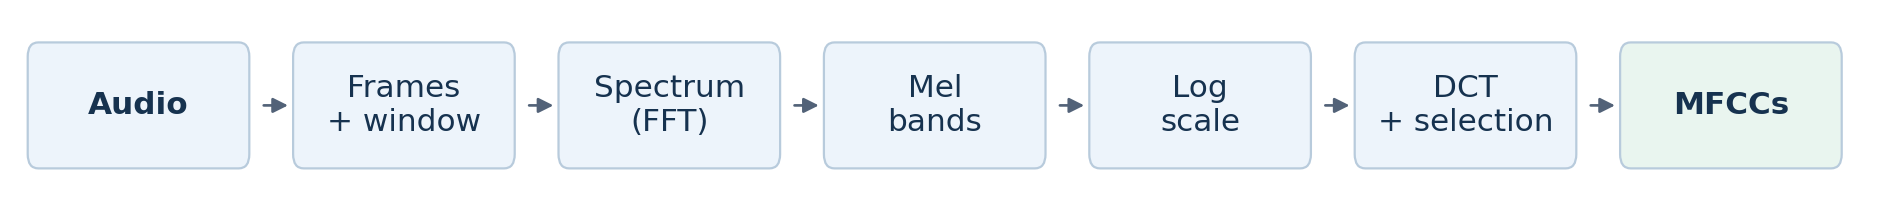

The full pipeline consists of these steps:

1. **Frames and window:** Split the recording into short, overlapping slices and smooth their edges.
2. **Power spectrum (|FFT|²):** Measure how strongly different frequencies appear in each slice.
3. **Mel bands:** Group nearby frequencies using a scale inspired by human hearing.
4. **Logarithm:** Compress the range of power values so weaker components are less overshadowed.
5. **Cosine transform (DCT):** Describe the broad spectral shape using numerical coefficients.
6. **Select coefficients:** Keep a small set of numbers for each slice. These are the MFCC features.

*Figure 1. Original overview based on the librosa documentation [2-5].*

The formulas behind each step follow below; then we run the pipeline step by step on the speech clip from section (i).

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### MFCC pipeline in formulas

1. **Frames, window, power spectrum:** $P[m,k] = |X[m,k]|^2$ from the STFT above
   (typical speech settings: 20–30 ms Hann window, 10 ms hop).
2. **Mel scale** (HTK formula; librosa's default `htk=False` uses the very similar Slaney
   variant, linear below 1 kHz and logarithmic above):
   $$ \text{mel}(f) = 2595\,\log_{10}\!\left(1 + \frac{f}{700}\right) $$
3. **Mel filterbank:** $M$ (≈ 26–40) triangular filters $H_b[k]$ whose centres are equally
   spaced on the Mel scale between `fmin` and `fmax` (narrow at low, wide at high frequencies):
   $\;E[m,b] = \sum_k H_b[k]\,P[m,k]$.
4. **Logarithm:** $L[m,b] = \log\big(E[m,b] + \varepsilon\big)$ (librosa: `power_to_db`,
   i.e. $10\log_{10}$). Compresses the dynamic range; a gain or channel factor becomes an additive offset.
5. **DCT-II** over the $M$ bands and truncation to the first $Q \approx 13$ coefficients:
   $$ c[m,q] = \sum_{b=0}^{M-1} L[m,b]\,\cos\!\left(\frac{\pi q\,(b + \tfrac12)}{M}\right),
   \qquad q = 0,\dots,Q-1 $$
   (with `norm="ortho"` scaling in librosa). The DCT decorrelates the strongly correlated
   neighbouring bands; low $q$ = smooth spectral envelope (vocal tract, timbre), high $q$ = fine
   detail such as pitch harmonics, which is discarded. $c_0$ is proportional to the mean log energy (loudness).

*Remarks.* **Deltas:** temporal derivatives $\Delta c$ (and $\Delta\Delta c$, `librosa.feature.delta`)
are often appended (13 + 13 + 13 = 39 features per frame) to describe dynamics.
**CMVN:** the coefficients have very different scales ($c_0$ has by far the largest variance),
so standardize each coefficient: $\hat c_q = (c_q - \mu_q)/\sigma_q$. Per-recording mean
subtraction also removes stationary channel/microphone effects; for an ML model, fit a
`StandardScaler` on the training data only.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *applied to the libri1 clip with librosa defaults instead of the removed recorder/PocketSphinx settings*

#### Step 1: Power spectrum → Mel bands → logarithm

Nearby frequencies are combined into bands inspired by human hearing, and logarithmic compression balances their range. **The result describes broad frequency patterns over time.** We use 40 Mel bands up to 8 kHz on the power spectrogram `power` from section (ii) and convert to dB, exactly as `librosa.feature.mfcc` does internally. [3, 4]

Mel filterbank: (40, 257),  log-Mel representation: 40 bands x 1279 frames.


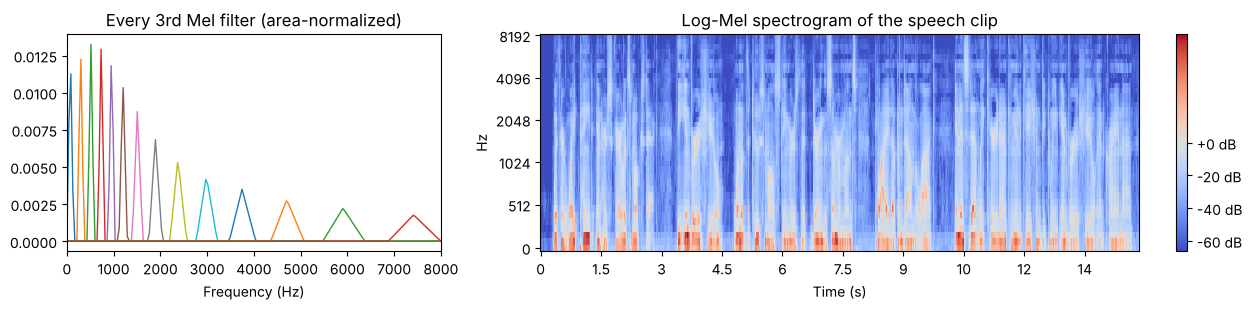

In [7]:
# [REVISED] librosa-standard filterbank on the example clip (PocketSphinx-specific filter weights removed)
N_MELS, N_MFCC, FMAX = 40, 13, 8000
mel_filters = librosa.filters.mel(sr=sr, n_fft=N_FFT, n_mels=N_MELS, fmax=FMAX)   # (40, 257)
mel_power = mel_filters @ power                  # filterbank energies E[m, b]
log_mel = librosa.power_to_db(mel_power)         # 10*log10(E), as inside librosa.feature.mfcc
print(f"Mel filterbank: {mel_filters.shape},  log-Mel representation: "
      f"{log_mel.shape[0]} bands x {log_mel.shape[1]} frames.")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 2]})
freqs = librosa.fft_frequencies(sr=sr, n_fft=N_FFT)
axes[0].plot(freqs, mel_filters[::3].T, linewidth=1)
axes[0].set(title="Every 3rd Mel filter (area-normalized)", xlabel="Frequency (Hz)", xlim=(0, FMAX))
img = librosa.display.specshow(log_mel, sr=sr, hop_length=HOP, x_axis="time", y_axis="mel",
                               fmax=FMAX, ax=axes[1])
axes[1].set(title="Log-Mel spectrogram of the speech clip", xlabel="Time (s)")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
fig.tight_layout()
plt.show()

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *liftering/recognizer weighting removed; one-liner check and CMVN added*

#### Step 2: DCT → 13 MFCC coefficients → standardization

The DCT-II of each log-Mel column gives the cepstral coefficients; we keep **13 coefficients per frame**. The heatmap shows how these features change during the sentence. Its vertical axis is **coefficient index**, rather than frequency. We also check that our step-by-step result equals the one-liner `librosa.feature.mfcc`, and show why per-coefficient standardization (CMVN) is needed before ML. [5]

MFCC matrix: 13 coefficients x 1279 frames; identical to librosa.feature.mfcc: True
Deltas (librosa.feature.delta) have the same shape: (13, 1279)
Std per coefficient before CMVN: [66.7 43.1 17.4 15.2 13.7 10.9  8.2 11.1  7.5  7.9  7.5  6.1  6.1]


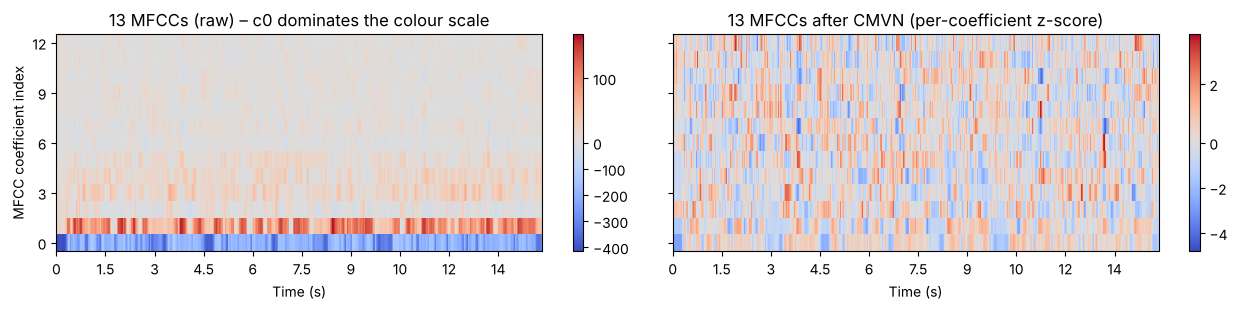

In [8]:
# [REVISED] standard librosa MFCC on the example clip; recognizer liftering removed; one-liner check and CMVN added
from scipy.fft import dct

mfcc = dct(log_mel, type=2, axis=0, norm="ortho")[:N_MFCC]          # DCT-II, keep c0..c12
mfcc_lib = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT,
                                hop_length=HOP, n_mels=N_MELS, fmax=FMAX)
print(f"MFCC matrix: {mfcc.shape[0]} coefficients x {mfcc.shape[1]} frames; "
      f"identical to librosa.feature.mfcc: {np.allclose(mfcc, mfcc_lib, atol=1e-3)}")
print(f"Deltas (librosa.feature.delta) have the same shape: {librosa.feature.delta(mfcc).shape}")

# CMVN: standardize each coefficient over time (per recording)
mfcc_cmvn = (mfcc - mfcc.mean(axis=1, keepdims=True)) / mfcc.std(axis=1, keepdims=True)
print("Std per coefficient before CMVN:", np.round(mfcc.std(axis=1), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, M, title in [(axes[0], mfcc, "13 MFCCs (raw) – c0 dominates the colour scale"),
                     (axes[1], mfcc_cmvn, "13 MFCCs after CMVN (per-coefficient z-score)")]:
    img = librosa.display.specshow(M, sr=sr, hop_length=HOP, x_axis="time", ax=ax)
    ax.set(title=title, xlabel="Time (s)", yticks=[0, 3, 6, 9, 12])
    fig.colorbar(img, ax=ax)
axes[0].set_ylabel("MFCC coefficient index")
fig.tight_layout()
plt.show()

<span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

*Live demo 'from your voice to features and words' (microphone recording with `sounddevice`, speech recognition with PocketSphinx `Decoder`/`process_cep`, model-specific feature settings, and the `%pip install` cell for these packages)* was removed: hardware-dependent and beyond the course topic list (speech recognition / model internals); the in-scope steps (STFT → Mel → log → DCT) are kept above on the librosa example clip.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

### Minimal application: MFCC features → standardization → logistic regression

A classifier needs **one fixed-length vector per example**, but a recording yields a
$13 \times n_\text{frames}$ MFCC matrix. For clip-level tasks (genre, speaker, machine state) a simple
choice is to pool over time: mean and standard deviation of every coefficient
→ $2 \cdot 13 = 26$ features per recording (time order is lost; for speech recognition one keeps
the sequence instead).

Evaluation must respect the data structure:
- **Split at the recording level.** Here each file gives exactly one vector, so every split is per
  file. If you cut several clips from one recording (or several tracks from one album/artist,
  several utterances from one speaker), use `GroupKFold` with the recording/artist/speaker as group,
  otherwise near-duplicates end up in train *and* test (leakage → optimistic accuracy).
- **Tiny, imbalanced data** (9 classical vs. 5 rock files): a single 50 % split leaves 7 test files,
  so one file changes the accuracy by 14 percentage points. We therefore use
  leave-one-**group**-out CV with the artist/work as group (7 of the 9 classical files are movements of
  the same work, *Achachak*; they must never be split between train and test). The scaler is refit
  inside every fold, and we compare with the majority-class baseline
  (9/14 = 64 %). The result is an illustration, not a reliable performance estimate.

Feature matrix: (14, 26) (recordings x features), classes: {'classic': 9, 'rock': 5}
8 artist/work groups: ['Achachak', 'Alex Morgan', 'Elephant Micah', 'FourSeasonsVivaldi', 'HoliznaCC0', 'NirvanaTheManWhoSoldTheWorld', 'SwanLakeTchaikovsky', 'TheRollingStonesPaintItBlack']


Leave-one-recording-out accuracy (optimistic): 71%  (balanced: 69%)
Leave-one-group-out accuracy: 50%  (balanced: 52%)
Majority-class baseline:       64%  (balanced: 50%)


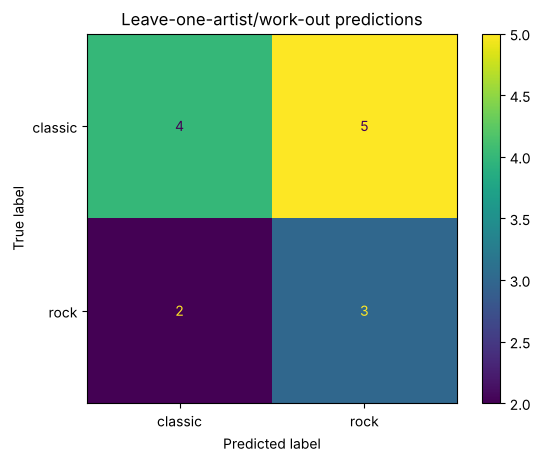

In [ ]:
# [CORRECTED] originally: 2 050 log-STFT features for 14 files with a single 50 % train/test
# split (7 test files, accuracy 71 % ≈ majority baseline). Now: 26 MFCC summary features per recording,
# leave-one-artist/work-out CV (several files are movements of the same work), balanced class weights and a majority baseline.
from sklearn.model_selection import LeaveOneGroupOut, LeaveOneOut, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score

def mfcc_features(file_path, n_mfcc=13):
    """One vector per recording: mean and std of each MFCC over time (2 * 13 = 26 numbers)."""
    y_clip, sr_clip = librosa.load(file_path, sr=SAMPLE_RATE, mono=True, duration=3 * CLIP_SECONDS)
    y_clip, _ = librosa.effects.trim(y_clip, top_db=40)      # drop leading/trailing silence
    y_clip = y_clip[:CLIP_SECONDS * sr_clip]                  # same clip length for every file
    M = librosa.feature.mfcc(y=y_clip, sr=sr_clip, n_mfcc=n_mfcc)
    return np.concatenate([M.mean(axis=1), M.std(axis=1)])

if files is None:
    print("Music folders missing – genre classification skipped.")
else:
    X_music = np.array([mfcc_features(p) for g in GENRES for p in files[g]])
    labels = np.array([g for g in GENRES for _ in files[g]])
    print(f"Feature matrix: {X_music.shape} (recordings x features), classes: "
          f"{ {g: int((labels == g).sum()) for g in GENRES} }")

    model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=1000, class_weight="balanced"))
    # group = artist/work (text before " - " in the file name): all movements of one work are held out together
    groups = np.array([str(p.stem.split(" - ")[0].strip()) for g in GENRES for p in files[g]])
    print(f"{len(set(groups))} artist/work groups: {sorted(set(groups.tolist()))}")
    cv = LeaveOneGroupOut()                              # each artist/work is the test set once
    pred = cross_val_predict(model, X_music, labels, cv=cv, groups=groups)
    base = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_music, labels, cv=LeaveOneOut())  # "always classic"

    # for comparison: naive leave-one-recording-out (movements of the same work can be in train AND test)
    pred_loo = cross_val_predict(model, X_music, labels, cv=LeaveOneOut())
    print(f"Leave-one-recording-out accuracy (optimistic): {accuracy_score(labels, pred_loo):.0%}  "
          f"(balanced: {balanced_accuracy_score(labels, pred_loo):.0%})")
    print(f"Leave-one-group-out accuracy: {accuracy_score(labels, pred):.0%}  "
          f"(balanced: {balanced_accuracy_score(labels, pred):.0%})")
    print(f"Majority-class baseline:       {accuracy_score(labels, base):.0%}  "
          f"(balanced: {balanced_accuracy_score(labels, base):.0%})")
    ConfusionMatrixDisplay.from_predictions(labels, pred, labels=GENRES)
    plt.title("Leave-one-artist/work-out predictions")
    plt.show()

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**What the numbers show.** With the naive leave-one-*recording*-out split the classifier reaches 71 %,
barely above the trivial "always classic" baseline (64 %). With the honest leave-one-*artist/work*-out split
it drops to about 50 %: when all *Achachak* movements are held out, the model has seen only two other
classical works and cannot generalize. The gap between the two numbers is exactly the **leakage** caused by
near-duplicate recordings in train and test. Lesson: MFCC summary statistics are a sensible feature vector,
but 14 recordings from 8 sources are far too few for a reliable genre classifier – the evaluation scheme
matters as much as the features.

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *demo references removed; CMVN and leakage pitfalls added*

### What does the example show?

The 14.8 s clip contains about 327 000 samples, but each short frame becomes just **13 numbers** (≈ 1 300 frames × 13). Their sequence preserves how the sound changes over time; pooled statistics (mean, std) give one vector per clip for clip-level classification. The MFCC coefficients themselves are only descriptions of sound – a trained model must interpret them. [5, 6]

### What problems do MFCCs address?

| Challenge | How MFCCs help |
|---|---|
| Many raw samples per second | Each short frame becomes a compact feature vector. |
| Sound changes over time | A sequence of frames tracks those changes. |
| A detailed spectrum has many frequency bins | Mel bands group nearby frequencies; retaining selected coefficients reduces dimensionality further. |
| Power values span a large range | Logarithmic compression balances the range. |
| Fine spectral detail can obscure broader patterns | Lower-order coefficients emphasize the broad spectral shape. |

Applications include **speech recognition, keyword spotting, speaker identification, and audio classification**. The feature representation must suit the task and the model that uses it. [6, 9]

### Limitations and common pitfalls

- **Noise and reverberation affect the features.** MFCC extraction does not automatically remove them. [7]
- **Some information is lost.** Truncated MFCCs omit phase information and some spectral detail, so they cannot uniquely reconstruct the recording. [8]
- **Features must match the model.** Keep extraction settings (sr, `n_fft`, hop, `n_mels`, `n_mfcc`, dB reference) identical for training and prediction. 13 coefficients is a common default, not a law. [5]
- **Unequal scales.** $c_0$ has a much larger variance than higher coefficients – standardize per coefficient (CMVN / `StandardScaler` fitted on training data).
- **Leakage.** Frames or clips from the same recording/speaker are highly correlated – split train/test by recording, speaker or artist (`GroupKFold`).
- **Time order matters.** Averaging all frames into one vector loses the sequence of sounds. Speech recognition needs a way to model that sequence. [6]

<span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> *resolution formulas, CMVN and leakage pitfalls added; demo reference removed*

## Takeaways

**What should every ML practitioner remember?**

- **`librosa`:** Provides tools to load audio, inspect waveforms, analyze frequencies, and extract features for machine learning.
- **STFT:** Analyzes short, overlapping windowed frames to show how frequency content changes over time. Resolution: Δf = sr/n_fft, Δt = hop/sr; longer windows trade time for frequency resolution. Features use magnitude or power (phase dropped), usually in dB.
- **MFCCs:** |STFT|² → Mel filterbank → log → DCT-II → keep ≈ 13 coefficients: a compact, decorrelated description of each frame's spectral envelope. Feature extraction describes the sound; a trained model interprets the feature sequence.

**What are common pitfalls?**

- **`librosa`:** Keep sampling rates, preprocessing, and feature settings consistent between training and prediction.
- **STFT:** Window size and hop affect the representation (e.g. the default `n_fft=2048` ≈ 93 ms at 22 kHz is long for speech). Do not mix `amplitude_to_db` and `power_to_db`. A spectrogram shows frequency patterns but does not directly identify words or sound classes.
- **MFCCs:** Noise and reverberation affect the features, and truncation loses information (pitch, phase). Standardize each coefficient (CMVN, scaler fitted on training data only), preserve temporal order when the task needs it, and split train/test by recording or speaker to avoid leakage. With a handful of recordings, accuracy is not meaningful – compare with a baseline.

**When do these techniques really matter?**

- **`librosa`:** When building audio processing workflows for speech, music, environmental sounds, or machine monitoring.
- **STFT:** When inspecting frequency patterns over time or preparing spectral representations for further feature extraction.
- **MFCCs:** When compact features describing spectral shape are useful, such as in speech recognition, keyword spotting, speaker identification, and audio classification.

<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *sources [10]–[12] of the removed recorder/recognizer demo replaced by MFCC, librosa and cross-validation references*

## References

The explanations, pipeline diagram, and examples use the sources below. Numbers in brackets refer to this list.

1. **librosa: Timbre and spectral content.** Spectral envelope, Mel representations, and MFCC intuition. https://librosa.org/doc/main/auto_tutorials/01-intro/07-timbre.html
2. **librosa: `stft`.** Windowing, Fourier analysis, and output frequency bins. https://librosa.org/doc/0.10.2/generated/librosa.stft.html
3. **librosa: `mel_frequencies`.** Perceptual frequency scale and Mel implementations. https://librosa.org/doc/main/api/generated/librosa.mel_frequencies.html
4. **librosa: `melspectrogram`.** Mel filter-bank mapping and power spectra. https://librosa.org/doc/0.10.2/generated/librosa.feature.melspectrogram.html
5. **librosa: `mfcc`.** Log-Mel input, DCT, coefficient selection, and output shape. https://librosa.org/doc/main/api/generated/librosa.feature.mfcc.html
6. **Jurafsky and Martin: Speech and Language Processing, archived speech recognition chapter.** Speech production, feature extraction, and temporal modeling. https://web.stanford.edu/~jurafsky/slp3/old_aug24/16.pdf
7. **Chiu and Stern: Minimum Variance Modulation Filter for Robust Speech Recognition.** Effects of background noise and reverberation. https://www.cs.cmu.edu/~ychiu/ychiu_web_files/MVMF.pdf
8. **Juvela et al.: Speech waveform synthesis from MFCC sequences with generative adversarial networks.** Additional modeling needed to synthesize speech from MFCCs. https://arxiv.org/abs/1804.00920
9. **Abdalla and Ali: Wavelet-Based Mel-Frequency Cepstral Coefficients for Speaker Identification using Hidden Markov Models.** Speaker identification with MFCC-derived features. https://arxiv.org/abs/1003.5627

10. **Davis and Mermelstein (1980): Comparison of parametric representations for monosyllabic word recognition in continuously spoken sentences.** IEEE TASSP 28(4). Original MFCC paper. https://doi.org/10.1109/TASSP.1980.1163420
11. **McFee et al. (2015): librosa: Audio and Music Signal Analysis in Python.** SciPy Proceedings. https://doi.org/10.25080/Majora-7b98e03b-003
12. **librosa: `feature.delta`.** Delta (derivative) features. https://librosa.org/doc/main/generated/librosa.feature.delta.html
13. **scikit-learn: Cross-validation (LeaveOneOut, GroupKFold).** https://scikit-learn.org/stable/modules/cross_validation.html

*Figure 1 is an original compact overview of the MFCC pipeline based on sources [2-5].*